# Progetto: Affidabilità Creditizia per il Rilascio della Carta di Credito

### di Lavinia Solimani

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, SGDClassifier, Perceptron
from sklearn.naive_bayes import GaussianNB, ComplementNB
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import RadiusNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import shuffle
from sklearn.metrics import log_loss, classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [3]:
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_theme(style = 'whitegrid')
RANDOM_SEED = 0

In [4]:
!wget https://proai-datasets.s3.eu-west-3.amazonaws.com/credit_scoring.csv

--2026-06-21 14:35:38--  https://proai-datasets.s3.eu-west-3.amazonaws.com/credit_scoring.csv
Resolving proai-datasets.s3.eu-west-3.amazonaws.com (proai-datasets.s3.eu-west-3.amazonaws.com)... 3.5.206.246, 3.5.206.133
Connecting to proai-datasets.s3.eu-west-3.amazonaws.com (proai-datasets.s3.eu-west-3.amazonaws.com)|3.5.206.246|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 46985859 (45M) [text/csv]
Saving to: ‘credit_scoring.csv’

credit_scoring.csv  100%[===================>]  44.81M  23.2MB/s    in 1.9s    

2026-06-21 14:35:41 (23.2 MB/s) - ‘credit_scoring.csv’ saved [46985859/46985859]



In [5]:
df = pd.read_csv('credit_scoring.csv')
df.head()

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,TARGET
0,5008804,M,Y,Y,0,424380.57,Working,Higher education,Civil marriage,Rented apartment,-11778.0,-4438.0,1.0,1.0,0.0,0.0,NaN,2.0,0
1,5008805,M,Y,Y,0,421593.52,Working,Higher education,Civil marriage,Rented apartment,-11777.0,-4459.0,1.0,1.0,0.0,0.0,NaN,2.0,0
2,5008806,M,Y,Y,0,110958.51,Working,Secondary / secondary special,Married,House / apartment,-21471.0,-1144.0,1.0,0.0,0.0,0.0,Security staff,2.0,0
3,5008808,F,N,Y,0,267497.96,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-18489.0,-3122.0,1.0,0.0,1.0,1.0,Sales staff,1.0,1
4,5008809,F,N,Y,0,263419.09,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19093.0,-3070.0,1.0,0.0,1.0,1.0,Sales staff,1.0,1


## Esplorazione del Dataset

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338427 entries, 0 to 338426
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   338427 non-null  int64  
 1   CODE_GENDER          338427 non-null  object 
 2   FLAG_OWN_CAR         338427 non-null  object 
 3   FLAG_OWN_REALTY      338427 non-null  object 
 4   CNT_CHILDREN         338427 non-null  int64  
 5   AMT_INCOME_TOTAL     338427 non-null  float64
 6   NAME_INCOME_TYPE     338427 non-null  object 
 7   NAME_EDUCATION_TYPE  338427 non-null  object 
 8   NAME_FAMILY_STATUS   338426 non-null  object 
 9   NAME_HOUSING_TYPE    338426 non-null  object 
 10  DAYS_BIRTH           338426 non-null  float64
 11  DAYS_EMPLOYED        338426 non-null  float64
 12  FLAG_MOBIL           338426 non-null  float64
 13  FLAG_WORK_PHONE      338426 non-null  float64
 14  FLAG_PHONE           338426 non-null  float64
 15  FLAG_EMAIL       

Il dataset è costituito da 338.427 osservazioni per 18 features e 1 target.

Innanzitutto rimuoviamo la variabile *ID*, in quanto è un codice univoco identificativo per ciascun cliente e, pertanto, non è utile alla costruzione del modello.

In [7]:
df = df.drop('ID', axis = 1)
df.head()

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,TARGET
0,M,Y,Y,0,424380.57,Working,Higher education,Civil marriage,Rented apartment,-11778.0,-4438.0,1.0,1.0,0.0,0.0,NaN,2.0,0
1,M,Y,Y,0,421593.52,Working,Higher education,Civil marriage,Rented apartment,-11777.0,-4459.0,1.0,1.0,0.0,0.0,NaN,2.0,0
2,M,Y,Y,0,110958.51,Working,Secondary / secondary special,Married,House / apartment,-21471.0,-1144.0,1.0,0.0,0.0,0.0,Security staff,2.0,0
3,F,N,Y,0,267497.96,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-18489.0,-3122.0,1.0,0.0,1.0,1.0,Sales staff,1.0,1
4,F,N,Y,0,263419.09,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19093.0,-3070.0,1.0,0.0,1.0,1.0,Sales staff,1.0,1


Verifichiamo se la variabile *TARGET* è bilanciata o meno all'interno del dataset.

In [8]:
target_summary = pd.DataFrame({
    'Count': df['TARGET'].value_counts(),
    'Percentage (%)': (df['TARGET'].value_counts(normalize = True)*100).round(1)
})

print(target_summary)

         Count  Percentage (%)
TARGET                        
0       308705            91.2
1        29722             8.8


Il dataset risulta essere estremamente sbilanciato, con il 91,2% di clienti che non ha un'alta affidabilità creditizia, e solamente l'8,8% che ce l'ha. Per poter costruire un modello predittivo efficace, dovremo tenere conto di questo problema.

Prima di costruire il modello, procederemo con un'analisi della correlazione tra le variabili, in modo da verificare l'eventuale presenza di multicollinearità e valutare se sia necessario eseguire una feature selection.

Innanzitutto, però, occorre gestire i dati mancanti e mappare i valori delle variabili non numeriche.

## Data Preprocessing

### Gestione dei Dati Mancanti

In [9]:
df.isna().sum()

,0
CODE_GENDER,0
FLAG_OWN_CAR,0
FLAG_OWN_REALTY,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0
NAME_FAMILY_STATUS,1
NAME_HOUSING_TYPE,1
DAYS_BIRTH,1


In [10]:
df['OCCUPATION_TYPE'].unique()

array([nan, 'Security staff', 'Sales staff', 'Accountants', 'Laborers',
       'Managers', 'Drivers', 'Core staff', 'High skill tech staff',
       'Cleaning staff', 'Private service staff', 'Cooking staff',
       'Low-skill Laborers', 'Medicine staff', 'Secretaries',
       'Waiters/barmen staff', 'HR staff', 'Realty agents', 'IT staff'],
      dtype=object)

Poiché non sappiamo quale lavoro svolgano i clienti che presentano il dato mancante in corrispondenza della variabile *OCCUPATION_TYPE* (è possibile che siano disoccupati), sostituiamo "NaN" con "Unknown".

In [11]:
df['OCCUPATION_TYPE'] = df['OCCUPATION_TYPE'].fillna('Unknown')
df.isna().sum()

,0
CODE_GENDER,0
FLAG_OWN_CAR,0
FLAG_OWN_REALTY,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0
NAME_FAMILY_STATUS,1
NAME_HOUSING_TYPE,1
DAYS_BIRTH,1


Verifichiamo ora se l'osservazione con valore mancante in corrispondenza della variabile *NAME_FAMILY_STATUS* è la stessa delle altre variabili.

In [12]:
df[df['NAME_FAMILY_STATUS'].isna()]

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,TARGET
338426,F,N,N,0,68765.48,Working,Secondary / se,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,NaN,0


Dato che l'osservazione è la stessa, in questo caso procediamo con l'eliminazione della riga dal dataset, in quanto ci sono troppe informazioni mancanti.

In [13]:
df = df.dropna(subset = ["NAME_FAMILY_STATUS"])
df.isna().sum()

,0
CODE_GENDER,0
FLAG_OWN_CAR,0
FLAG_OWN_REALTY,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0
NAME_FAMILY_STATUS,0
NAME_HOUSING_TYPE,0
DAYS_BIRTH,0


In [14]:
df.head()

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,TARGET
0,M,Y,Y,0,424380.57,Working,Higher education,Civil marriage,Rented apartment,-11778.0,-4438.0,1.0,1.0,0.0,0.0,Unknown,2.0,0
1,M,Y,Y,0,421593.52,Working,Higher education,Civil marriage,Rented apartment,-11777.0,-4459.0,1.0,1.0,0.0,0.0,Unknown,2.0,0
2,M,Y,Y,0,110958.51,Working,Secondary / secondary special,Married,House / apartment,-21471.0,-1144.0,1.0,0.0,0.0,0.0,Security staff,2.0,0
3,F,N,Y,0,267497.96,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-18489.0,-3122.0,1.0,0.0,1.0,1.0,Sales staff,1.0,1
4,F,N,Y,0,263419.09,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19093.0,-3070.0,1.0,0.0,1.0,1.0,Sales staff,1.0,1


## Verifica di dati duplicati

In [15]:
df.duplicated().sum()

np.int64(0)

Dal momento che non sono presenti osservazioni duplicate, procediamo oltre.

Gestiamo le variabili *DAYS_BIRTH* (numero di giorni trascorsi dalla nascita) e *DAYS_EMPLOYED* (numero di giorni trascorsi dalla data di assunzione), in quanto i valori rappresentati in giorni e negativi sono poco intuitivi.

Nel caso di *DAYS_BIRTH*, prendiamo il valore assoluto e lo dividiamo per 365, in modo da ottenere gli anni di età.

Per *DAYS_EMPLOYED*, invece, creiamo una variabile binaria *IS_EMPLOYED* che indichi 1 se il cliente ha un'occupazione e 0 se è disoccupato, dopodiché creiamo un'altra variabile *YEARS_EMPLOYED* che riporterà gli anni di occupazione.

Al termine, eliminiamo le variabili originali dal dataset.

In [ ]:
df.loc[:, 'AGE_YEARS'] = np.abs(df['DAYS_BIRTH']) / 365
df = df.drop('DAYS_BIRTH', axis = 1)

df.loc[:, 'IS_EMPLOYED'] = df['DAYS_EMPLOYED'].apply(lambda x : 1 if x <= 0 else 0)
df.loc[:, 'YEARS_EMPLOYED'] = df['DAYS_EMPLOYED'].apply(lambda x : np.abs(x)/365 if x <= 0 else 0)
df = df.drop('DAYS_EMPLOYED', axis = 1)

df.head()

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,TARGET,AGE_YEARS,IS_EMPLOYED,YEARS_EMPLOYED
0,M,Y,Y,0,424380.57,Working,Higher education,Civil marriage,Rented apartment,1.0,1.0,0.0,0.0,Unknown,2.0,0,32.268493,1,12.158904
1,M,Y,Y,0,421593.52,Working,Higher education,Civil marriage,Rented apartment,1.0,1.0,0.0,0.0,Unknown,2.0,0,32.265753,1,12.216438
2,M,Y,Y,0,110958.51,Working,Secondary / secondary special,Married,House / apartment,1.0,0.0,0.0,0.0,Security staff,2.0,0,58.824658,1,3.134247
3,F,N,Y,0,267497.96,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1.0,0.0,1.0,1.0,Sales staff,1.0,1,50.654795,1,8.553425
4,F,N,Y,0,263419.09,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1.0,0.0,1.0,1.0,Sales staff,1.0,1,52.309589,1,8.410959


### Esplorazione dei Dati

Ora esploriamo la relazione tra il target e le variabili relative al reddito annuale, al tipo di reddito, al tipo di istruzione, allo stato civile, al tipo di abitazione e al tipo di occupazione.

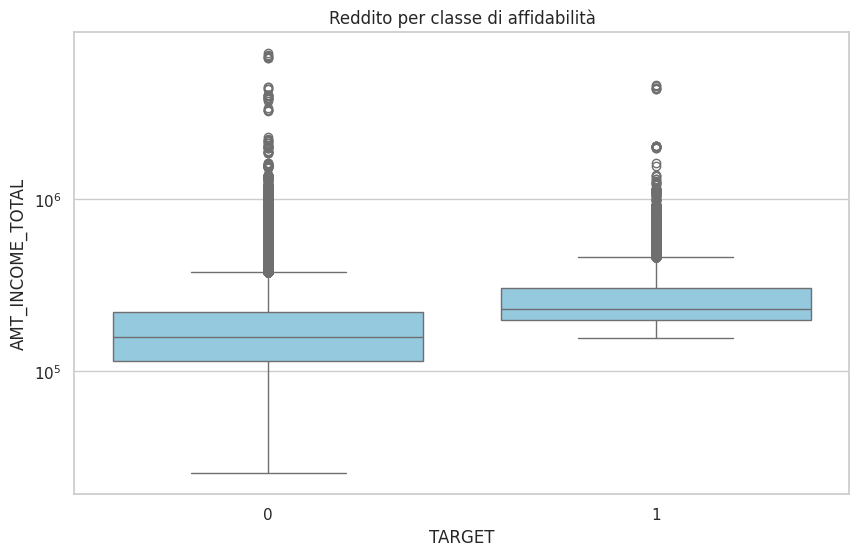

In [ ]:
sns.boxplot(x = 'TARGET', y = 'AMT_INCOME_TOTAL', data = df, color = 'skyblue')
plt.yscale('log')
plt.title('Reddito per classe di affidabilità')
plt.show()

Il grafico mostra che il reddito annuo del cliente ha un impatto sulla sua affidabilità creditizia, in quanto la distribuzione del reddito per i clienti che hanno un'elevata affidabilità è su valori generalmente più alti rispetto ai clienti con bassa affidabilità. Tuttavia, si possono notare molti outliers in entrambe le distribuzioni, quindi ci sono anche casi di clienti con un reddito molto alto che, però, non hanno una buona affidabilità creditizia.

Proviamo ora ad aggiungere l'interazione con la variabile relativa all'età, visualizzando il risultato in uno scatterplot.

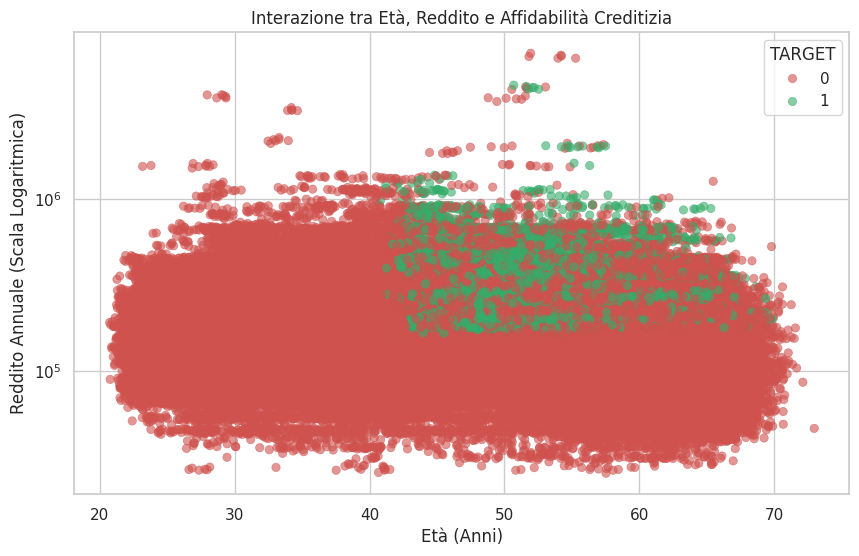

In [ ]:
sns.scatterplot(x = 'AGE_YEARS',
                y = 'AMT_INCOME_TOTAL',
                hue = 'TARGET',
                data = df,
                palette = ['#cf524e', '#35ad6b'],
                alpha = 0.6,
                edgecolor = None)
plt.yscale('log')
plt.title('Interazione tra Età, Reddito e Affidabilità Creditizia')
plt.xlabel('Età (Anni)')
plt.ylabel('Reddito Annuale (Scala Logaritmica)')
plt.show()

Aggiungendo la variabile dell'età si può notare che, in questo dataset, l'affidabilità creditizia è presente esclusivamente nei clienti che hanno almeno 40 anni. La nuvola di punti verdi che indicano una buona affidabilità creditizia, infatti, sono posizionati in alto a destra nel grafico, pertanto i clienti che pagano le rate con costanza si riscontrano dopo una certa età e oltre una determinata soglia di reddito annuo.

Ora passiamo ad esaminare la relazione tra la variabile target, ovvero l'affidabilità creditizia, e la variabile relativa al tipo di istruzione.

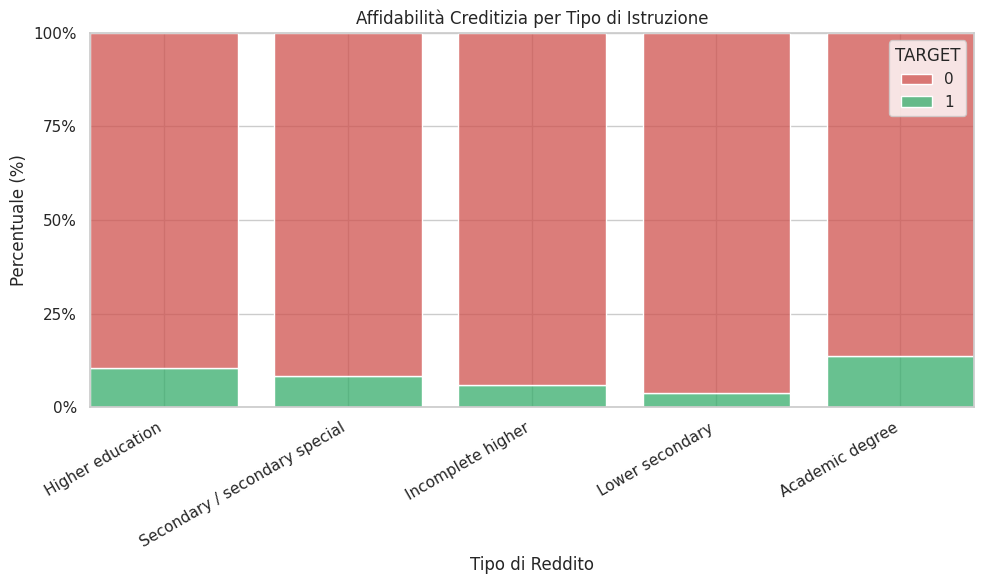

In [ ]:
sns.histplot(data = df,
             x = 'NAME_EDUCATION_TYPE',
             hue = 'TARGET',
             multiple = 'fill',
             stat = 'count',
             palette = {0 : '#cf524e', 1 : '#35ad6b'},
             shrink = 0.8,
             hue_order = [0, 1]
             )
plt.title('Affidabilità Creditizia per Tipo di Istruzione')
plt.xlabel('Tipo di Reddito')
plt.ylabel('Percentuale (%)')
plt.xticks(rotation = 30, ha = 'right')
plt.yticks(ticks = [0, 0.25, 0.5, 0.75, 1], labels = ['0%', '25%', '50%', '75%', '100%'])
plt.tight_layout()
plt.show()

Dal grafico si notano alcune differenze nella distribuzione tra elevata affidabilità e bassa affidabilità creditizia in base al tipo di istruzione del cliente. Si nota, ad esempio, che la frequenza maggiore di clienti con un'elevata affidabilità creditizia si trova nella categoria relativa al diploma universitario, mentre le frequenze minori si trovano nelle categorie relative alla scuola secondaria di primo e secondo grado.

Vediamo ora la relazione tra il target e la variabile relativa al tipo di reddito.

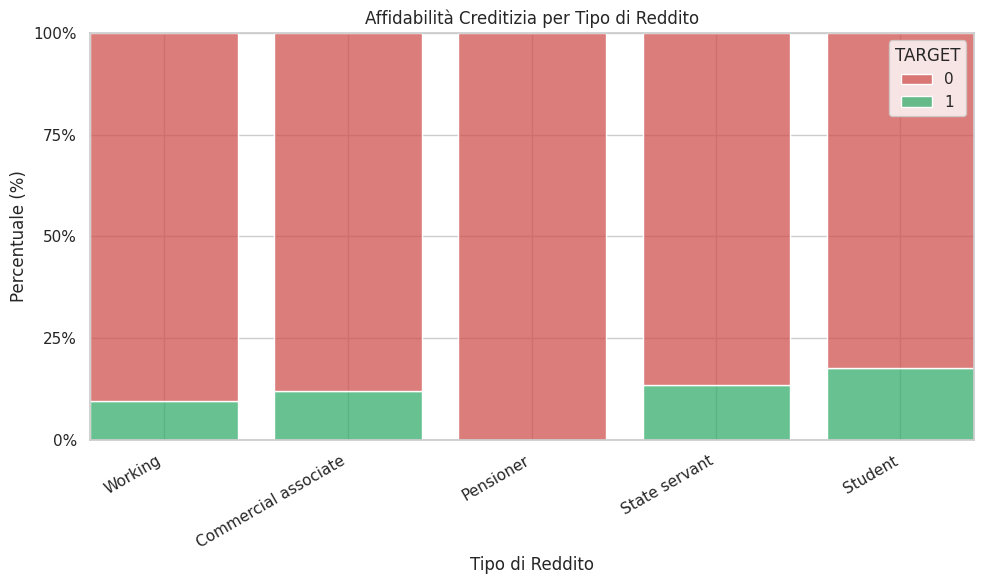

In [ ]:
sns.histplot(data = df,
             x = 'NAME_INCOME_TYPE',
             hue = 'TARGET',
             multiple = 'fill',
             stat = 'count',
             palette = {0 : '#cf524e', 1 : '#35ad6b'},
             shrink = 0.8,
             hue_order = [0, 1]
             )
plt.title('Affidabilità Creditizia per Tipo di Reddito')
plt.xlabel('Tipo di Reddito')
plt.ylabel('Percentuale (%)')
plt.xticks(rotation = 30, ha = 'right')
plt.yticks(ticks = [0, 0.25, 0.5, 0.75, 1], labels = ['0%', '25%', '50%', '75%', '100%'])
plt.tight_layout()
plt.show()

Dal grafico si può notare subito che, in questo dataset, nessuno dei clienti pensionati ha una buona affidabilità creditizia, mentre gli studenti sono la categoria che presenta il maggior numero di clienti con elevata affidabilità creditizia, sebbene la percentuale sia solamente del 20% circa.

Analizziamo ora la relazione tra il target e lo stato civile del cliente, per verificare se alcune situazioni familiari possono essere correlate a una maggiore stabilità finanziaria e, quindi, a un'affidabilità creditizia più elevata.

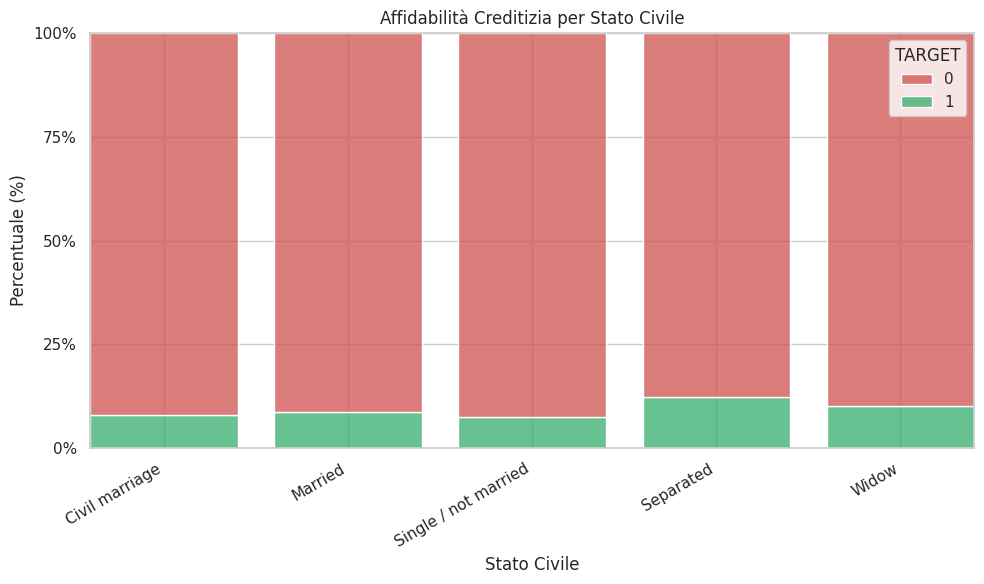

In [ ]:
sns.histplot(data = df,
             x = 'NAME_FAMILY_STATUS',
             hue = 'TARGET',
             multiple = 'fill',
             stat = 'count',
             palette = {0 : '#cf524e', 1 : '#35ad6b'},
             shrink = 0.8,
             hue_order = [0, 1]
             )
plt.title('Affidabilità Creditizia per Stato Civile')
plt.xlabel('Stato Civile')
plt.ylabel('Percentuale (%)')
plt.xticks(rotation = 30, ha = 'right')
plt.yticks(ticks = [0, 0.25, 0.5, 0.75, 1], labels = ['0%', '25%', '50%', '75%', '100%'])
plt.tight_layout()
plt.show()

Dal grafico non si evincono differenze sostanziali nella distribuzione della variabile target in base allo stato civile. Pertanto, questo aspetto che riguarda il cliente non sembra avere un impatto sulla sua affidabilità creditizia.

Vediamo ora la relazione tra il target e il tipo di abitazione in cui risiede il cliente. Un'ipotesi comune può essere che i clienti che vivono in affitto, con i genitori o in una casa popolare abbiano meno stabilità economica dei clienti che possiedono una casa di proprietà.

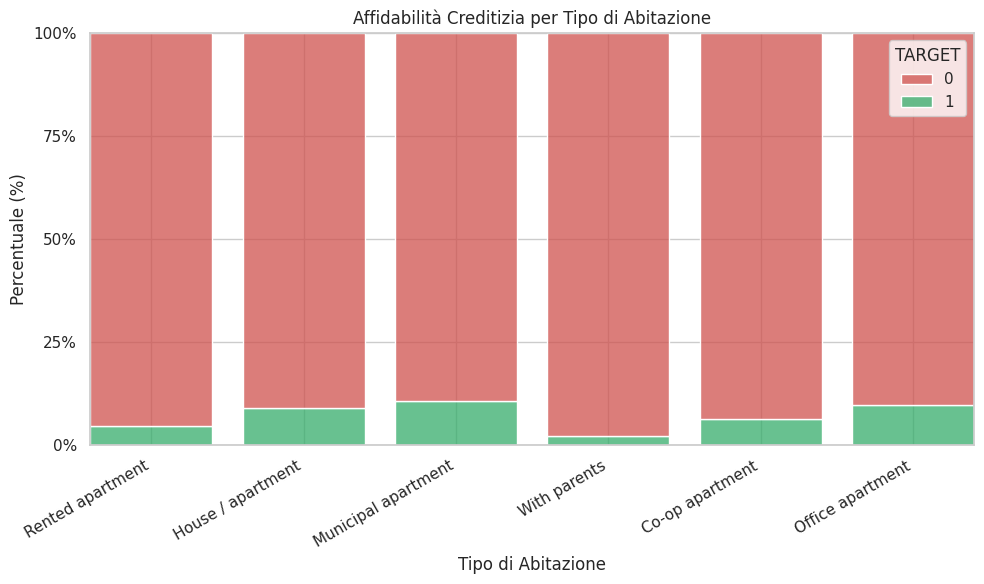

In [ ]:
sns.histplot(data = df,
             x = 'NAME_HOUSING_TYPE',
             hue = 'TARGET',
             multiple = 'fill',
             stat = 'count',
             palette = {0 : '#cf524e', 1 : '#35ad6b'},
             shrink = 0.8,
             hue_order = [0, 1]
             )
plt.title('Affidabilità Creditizia per Tipo di Abitazione')
plt.xlabel('Tipo di Abitazione')
plt.ylabel('Percentuale (%)')
plt.xticks(rotation = 30, ha = 'right')
plt.yticks(ticks = [0, 0.25, 0.5, 0.75, 1], labels = ['0%', '25%', '50%', '75%', '100%'])
plt.tight_layout()
plt.show()

Dal grafico possiamo vedere che questa variabile ha un impatto sull'affidabilità creditizia. L'ipotesi è confermata per quanto riguarda i clienti che vivono in affitto o con i genitori, mentre, sorprendentemente, la categoria di clienti che vive in una casa popolare è quella con la frequenza maggiore di elevata affidabilità creditizia.

Infine, esaminiamo la relazione tra il target e il tipo di occupazione. Per creare il grafico, prendiamo in considerazione solamente i clienti con una bassa affidabilità creditizia.

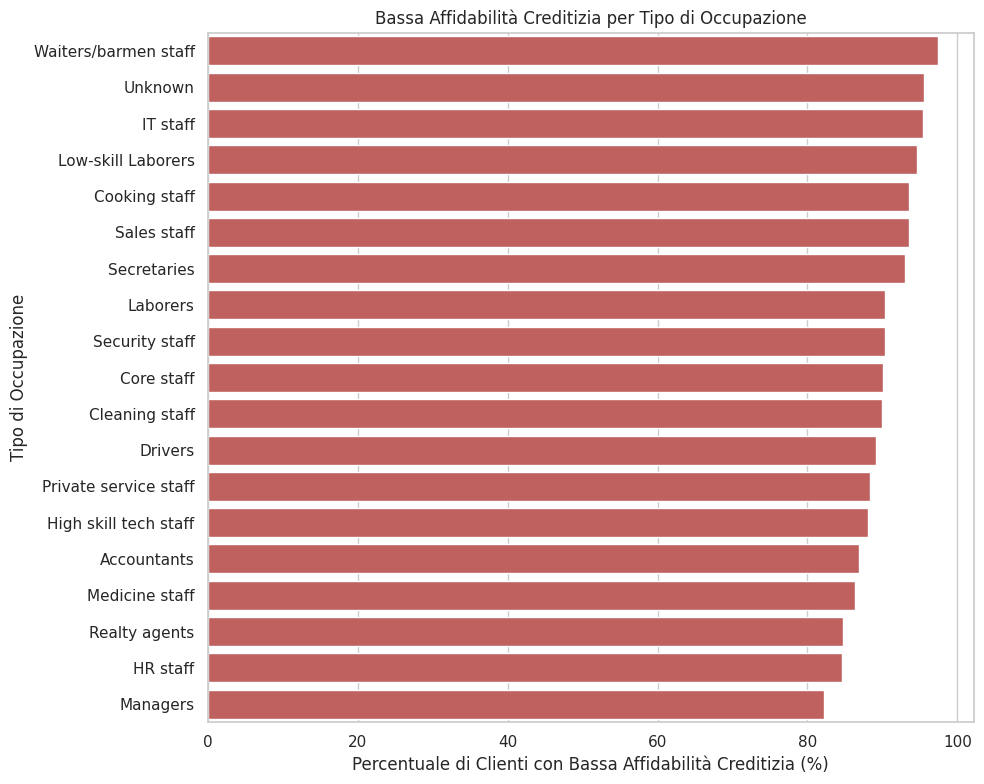

In [ ]:
df['LOW_CRED'] = 1 - df['TARGET']
occupation_cred_stats = df.groupby('OCCUPATION_TYPE')['LOW_CRED'].mean().reset_index()
occupation_cred_stats['LOW_RATE'] = occupation_cred_stats['LOW_CRED'] * 100
occupation_cred_stats = occupation_cred_stats.sort_values(by = 'LOW_RATE', ascending = False)

plt.figure(figsize = (10, 8))
sns.barplot(data = occupation_cred_stats,
            x = 'LOW_RATE',
            y = 'OCCUPATION_TYPE',
            color = '#cf524e')
plt.title('Bassa Affidabilità Creditizia per Tipo di Occupazione')
plt.xlabel('Percentuale di Clienti con Bassa Affidabilità Creditizia (%)')
plt.ylabel('Tipo di Occupazione')
plt.tight_layout()
plt.show()

Dal grafico si nota come, in questo dataset, per alcune professioni i clienti che hanno una bassa affidabilità creditizia arrivino quasi al 100%, mentre per altre professioni questa percentuale scende a poco più dell'80%. Pertanto, la professione del cliente è un elemento che influisce sulla sua affidabilità creditizia.

### Label e Ordinal Encoding

Procediamo ora con il Label Encoding per le variabili binarie, e con l'Ordinal Encoding per le variabili categoriali ordinate.

In [ ]:
df['NAME_EDUCATION_TYPE'].unique()

array(['Higher education', 'Secondary / secondary special',
       'Incomplete higher', 'Lower secondary', 'Academic degree'],
      dtype=object)

In [ ]:
# Label Encoding
df['CODE_GENDER'] = df['CODE_GENDER'].map({'M' : 1, 'F' : 0})
df['FLAG_OWN_CAR'] = df['FLAG_OWN_CAR'].map({'Y' : 1, 'N' : 0})
df['FLAG_OWN_REALTY'] = df['FLAG_OWN_REALTY'].map({'Y' : 1, 'N' : 0})

# Ordinal Encoding
education_order = ['Lower secondary',
                   'Secondary / se',
                   'Secondary / secondary special',
                   'Incomplete higher',
                   'Higher education',
                   'Academic degree']

education_mapping = {level : index for index, level in enumerate(education_order)}
df['NAME_EDUCATION_TYPE'] = df['NAME_EDUCATION_TYPE'].map(education_mapping)

df.head()

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,TARGET,AGE_YEARS,IS_EMPLOYED,YEARS_EMPLOYED,LOW_CRED
0,1,1,1,0,424380.57,Working,4,Civil marriage,Rented apartment,1.0,1.0,0.0,0.0,Unknown,2.0,0,32.268493,1,12.158904,1
1,1,1,1,0,421593.52,Working,4,Civil marriage,Rented apartment,1.0,1.0,0.0,0.0,Unknown,2.0,0,32.265753,1,12.216438,1
2,1,1,1,0,110958.51,Working,2,Married,House / apartment,1.0,0.0,0.0,0.0,Security staff,2.0,0,58.824658,1,3.134247,1
3,0,0,1,0,267497.96,Commercial associate,2,Single / not married,House / apartment,1.0,0.0,1.0,1.0,Sales staff,1.0,1,50.654795,1,8.553425,0
4,0,0,1,0,263419.09,Commercial associate,2,Single / not married,House / apartment,1.0,0.0,1.0,1.0,Sales staff,1.0,1,52.309589,1,8.410959,0


Vediamo ora le statistiche di sintesi delle variabili.

In [ ]:
df.describe()

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_EDUCATION_TYPE,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,TARGET,AGE_YEARS,IS_EMPLOYED,YEARS_EMPLOYED,LOW_CRED
count,338426.000000,338426.000000,338426.000000,338426.000000,3.384260e+05,338426.000000,338426.0,338426.000000,338426.000000,338426.000000,338426.000000,338426.000000,338426.000000,338426.000000,338426.000000,338426.000000
mean,0.326544,0.370040,0.683479,0.428936,1.876689e+05,2.555079,1.0,0.211379,0.293302,0.105181,2.197228,0.087824,43.830720,0.829088,5.987951,0.912176
std,0.468950,0.482816,0.465120,0.727991,1.107863e+05,0.919542,0.0,0.408287,0.455276,0.306787,0.899570,0.283040,11.487914,0.376432,6.601064,0.283040
min,0.000000,0.000000,0.000000,0.000000,2.554898e+04,0.000000,1.0,0.000000,0.000000,0.000000,1.000000,0.000000,20.728767,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,1.212306e+05,2.000000,1.0,0.000000,0.000000,0.000000,2.000000,0.000000,34.291096,1.000000,1.035616,1.000000
50%,0.000000,0.000000,1.000000,0.000000,1.628556e+05,2.000000,1.0,0.000000,0.000000,0.000000,2.000000,0.000000,42.802740,1.000000,4.063014,1.000000
75%,1.000000,1.000000,1.000000,1.000000,2.252082e+05,4.000000,1.0,0.000000,1.000000,0.000000,3.000000,0.000000,53.334247,1.000000,8.536986,1.000000
max,1.000000,1.000000,1.000000,19.000000,7.071016e+06,5.000000,1.0,1.000000,1.000000,1.000000,20.000000,1.000000,72.975342,1.000000,49.241096,1.000000


Osservando i valori medi, possiamo fare queste considerazioni:

*   L'età media nel dataset è di circa 44 anni.
*   La media di *CODE_GENDER* è di circa 0.33, indicando un certo sbilanciamento nella composizione, con più donne (= 0) rispetto a uomini (= 1).
*   La media di *IS_EMPLOYED* è di circa 0.83, quindi la maggior parte dei clienti ha un'occupazione.
*   La media di *YEARS_EMPLOYED* è di circa 6 anni, mentre è presente un valore massimo di 49 anni.
*   La media di *FLAG_OWN_CAR* è di circa 0.37, quindi la maggior parte dei clienti in questo dataset non possiede un'automobile.
*   La media di *FLAG_OWN_REALTY* è di circa 0.68, quindi la maggior parte dei clienti possiede una casa.
*   La media di *CNT_CHILDREN*, ovvero del numero di figli, è di circa 0.43, mentre il valore massimo rilevato è 19.
*   La media di *CNT_FAM_MEMBERS*, ovvero del numero di familiari, è di circa 2.2, mentre il valore massimo rilevato è 20.
*   La media di *AMT_INCOME_TOTAL*, ovvero del reddito annuo del cliente, è di 187.668,4.

Un altro aspetto da notare è che la variabile *FLAG_MOBIL* ha media 1 e deviazione standard 0, quindi significa che tutte le osservazioni del dataset presentano valore pari a 1.

Verifichiamo quale osservazione presenta il numero massimo di anni lavorati, ovvero 49.

In [ ]:
df.loc[df['YEARS_EMPLOYED'].idxmax()]

,102189
CODE_GENDER,0
FLAG_OWN_CAR,1
FLAG_OWN_REALTY,1
CNT_CHILDREN,0
AMT_INCOME_TOTAL,132848.74
NAME_INCOME_TYPE,Working
NAME_EDUCATION_TYPE,2
NAME_FAMILY_STATUS,Widow
NAME_HOUSING_TYPE,House / apartment
FLAG_MOBIL,1.0


Si tratta di una donna di 65 anni, che ha quindi iniziato a lavorare quando aveva 16 anni.

### Analisi delle Correlazioni

Ora procediamo con l'analisi della correlazione tra le features e il target, rappresentandola graficamente tramite heatmap. Escluderemo da quest'analisi le variabili categoriali su scala nominale, mentre manterremo la variabile *NAME_EDUCATION_TYPE*, che è categoriale su scala ordinale. Per poterla analizzare correttamente, anziché il coefficiente di correlazione lineare di Pearson, utilizzeremo il coefficiente di cograduazione di Spearman.

Inoltre, poiché abbiamo visto che la variabile *FLAG_MOBIL* ha deviazione standard pari a 0, non ha senso includerla nella matrice di correlazione.

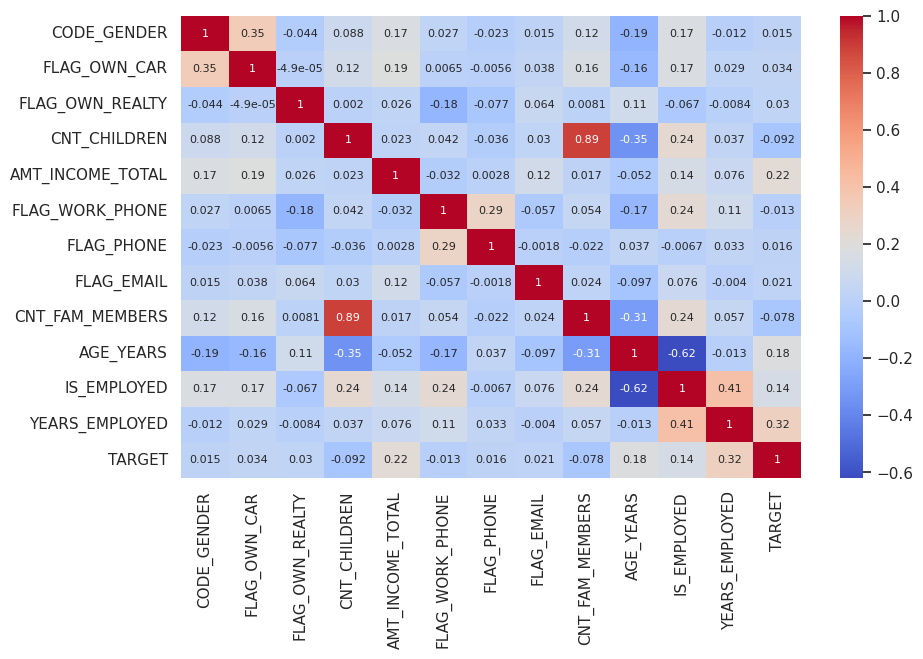

In [ ]:
heatmap_features = df[['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
                       'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'FLAG_WORK_PHONE',
                       'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'AGE_YEARS',
                       'IS_EMPLOYED', 'YEARS_EMPLOYED', 'TARGET']]
sns.heatmap(heatmap_features.corr(),
            annot = True,
            annot_kws = {'size':8},
            cmap = 'coolwarm')
plt.show()

Una prima osservazione che possiamo fare guardando la matrice è l'assenza di valori per la variabile *FLAG_MOBIL*.

Osservando innanzitutto la variabile *TARGET*, si può constatare una maggiore correlazione con le seguenti features:

*   *YEARS_EMPLOYED* (correlazione positiva, $r = 0.32$)
*   *AMT_INCOME_TOTAL* (correlazione positiva, $r = 0.22$)
*   *AGE_YEARS* (correlazione positiva, $r = 0.18$)
*   *IS_EMPLOYED* (correlazione positiva, $r = 0.14$)

Pertanto, le features più significative per una previsione dell'affidabilità creditizia di un cliente sono gli anni di occupazione lavorativa e il reddito annuo, seguite dall'età e dal fatto che il cliente abbia effettivamente un'occupazione. Nello specifico, maggiori sono gli anni di occupazione lavorativa, il reddito e l'età, maggiore tende ad essere l'affidabilità creditizia.

Ora, invece, esploriamo le correlazioni più significative tra features, che possono rivelare un problema di multicollinearità nel dataset:

*   *CNT_CHILDREN* e *CNT_FAMILY_MEMBERS* presentano la correlazione maggiormente positiva di tutto il dataset, con $r = 0.89$. Questo era prevedibile in quanto, all'aumentare dei figli, aumenta il numero dei membri della famiglia.
*   *AGE_YEARS* e *IS_EMPLOYED* presentano la correlazione maggiormente negativa di tutto il dataset, con $r = -0.62$. Ciò significa che, più un cliente è giovane, meno tende ad avere un'occupazione lavorativa (per esempio, nel caso di studenti).
*   *AGE_YEARS* è anche negativamente correlato con *CNT_CHILDREN* ($r = -0.35$) e con *CNT_FAMILY_MEMBERS* ($r = -0.31$), indicando che i clienti più giovani hanno meno figli e, quindi, famiglie meno numerose.

Da quest'analisi emerge, quindi, un rischio di multicollinearità, specialmente tra le coppie di variabili *CNT_CHILDREN* - *CNT_FAMILY_MEMBERS* e *AGE_YEARS* - *IS_EMPLOYED*, che dovremo monitorare in fase di valutazione del modello.

Definiamo ora l'array delle features e l'array del target, nonché le liste delle features che ci serviranno per il One-hot Encoding e per il Feature Scaling.

In [ ]:
X = df.drop(['TARGET', 'LOW_CRED'], axis = 1)
X.shape

(338426, 18)

In [ ]:
y = df['TARGET']
y.shape

(338426,)

In [ ]:
numerical_features = ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS',
                      'AGE_YEARS', 'YEARS_EMPLOYED', 'NAME_EDUCATION_TYPE']
categorical_features = ['NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS',
                        'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']

## Costruzione del Modello Predittivo

Procederemo con la costruzione di diversi modelli di classificazione, definendo per ciascuno di essi una pipeline comprensiva di Data Preprocessing (suddivisione in set di addestramento e di test, One-hot Encoding e Feature Scaling), addestramento del modello, e Scoring.

Definiamo innanzitutto una funzione che utilizzeremo per valutare i modelli.

In [ ]:
def evaluate_model(model, data):
  X, y = data
  y_pred = model.predict(X)
  print(classification_report(y, y_pred))
  print(f'Confusion Matrix: \n{confusion_matrix(y, y_pred)}')

I modelli che andremo ad addestrare sono:


1.   Regressione Logistica
2.   Stochastic Gradient Descent Classifier
3.   Mini Batch Gradient Descent Classifier
4.   Gaussian Naive Bayes
5.   Complement Naive Bayes
6.   Linear Support Vector Classifier
7.   Perceptron
8.   Multilayer Perceptron
9.   Decision Tree Classifier
10.  Random Forest Classifier

### 1. Regressione Logistica

In [ ]:
"""
TRAIN AND TEST SET SPLITTING
"""
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size = .2,
                                                    random_state = RANDOM_SEED,
                                                    stratify = y) # Maintain class proportions in train and test set

"""
DATA PREPROCESSING
"""
preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', StandardScaler(), numerical_features),
        ('categorical', OneHotEncoder(drop = 'first'), categorical_features) # Avoid multicollinearity
        ],
    remainder = 'passthrough'
    )

pipeline_lr = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight = 'balanced'))
    ]
                    )


"""
MODEL FITTING
"""
pipeline_lr.fit(X_train, y_train)


"""
MODEL EVALUATION
"""
print('TRAIN SET \n')
evaluate_model(pipeline_lr, (X_train, y_train))
print(f'\nLog Loss: {log_loss(y_train, pipeline_lr.predict_proba(X_train)):.3f}')
print()
print('TEST SET \n')
evaluate_model(pipeline_lr, (X_test, y_test))
print(f'\nLog Loss: {log_loss(y_test, pipeline_lr.predict_proba(X_test)):.3f}')

TRAIN SET 

              precision    recall  f1-score   support

           0       0.99      0.82      0.90    246962
           1       0.32      0.88      0.47     23778

    accuracy                           0.82    270740
   macro avg       0.65      0.85      0.68    270740
weighted avg       0.93      0.82      0.86    270740

Confusion Matrix: 
[[202339  44623]
 [  2789  20989]]

Log Loss: 0.406

TEST SET 

              precision    recall  f1-score   support

           0       0.99      0.82      0.90     61742
           1       0.33      0.89      0.48      5944

    accuracy                           0.83     67686
   macro avg       0.66      0.86      0.69     67686
weighted avg       0.93      0.83      0.86     67686

Confusion Matrix: 
[[50724 11018]
 [  632  5312]]

Log Loss: 0.404


### 2. Stochastic Gradient Descent Classifier

In [ ]:
"""
TRAIN AND TEST SET SPLITTING
"""
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size = .2,
                                                    random_state = RANDOM_SEED,
                                                    stratify = y)

"""
DATA PREPROCESSING
"""
preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', StandardScaler(), numerical_features),
        ('categorical', OneHotEncoder(drop = 'first'), categorical_features)
        ],
    remainder = 'passthrough'
    )


X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)


"""
MODEL FITTING
"""
sgd = SGDClassifier(class_weight = 'balanced')
sgd.fit(X_train, y_train)


"""
MODEL EVALUATION
"""
print('TRAIN SET \n')
evaluate_model(sgd, (X_train, y_train))
print()
print('TEST SET \n')
evaluate_model(sgd, (X_test, y_test))

TRAIN SET 

              precision    recall  f1-score   support

           0       0.99      0.80      0.89    246962
           1       0.31      0.91      0.46     23778

    accuracy                           0.81    270740
   macro avg       0.65      0.86      0.67    270740
weighted avg       0.93      0.81      0.85    270740

Confusion Matrix: 
[[198609  48353]
 [  2238  21540]]

TEST SET 

              precision    recall  f1-score   support

           0       0.99      0.81      0.89     61742
           1       0.31      0.91      0.47      5944

    accuracy                           0.82     67686
   macro avg       0.65      0.86      0.68     67686
weighted avg       0.93      0.82      0.85     67686

Confusion Matrix: 
[[49760 11982]
 [  511  5433]]


### 3. Mini Batch Gradient Descent Classifier

In [ ]:
def fit(model, X, y, batch_size = 1, epochs = 100, verbose = True):

  n_batches = int(X.shape[0]//batch_size)+1
  classes = np.unique(y)

  batch_loss = []

  for epoch in range(epochs):
    X_shuffled, y_shuffled = shuffle(X, y)

    for batch in range(n_batches):
      batch_start = int(batch*batch_size)
      batch_end = int((batch+1)*batch_size)
      X_batch = X_shuffled[batch_start:batch_end, :]
      y_batch = y_shuffled[batch_start:batch_end]
      model.partial_fit(X_batch, y_batch, classes = classes)

    # Log Loss calculated once per epoch, instead of once per batch
    loss = log_loss(y_test, model.predict_proba(X_test), labels = classes)
    batch_loss.append(loss)

    if verbose:
      print(f'Loss all\'epoca {epoch+1} = {loss}')

  return model


def evaluate(model, X, y, label = None):

  y_pred = model.predict(X)
  y_proba = model.predict_proba(X)

  if label is not None:
    print(label)

  scores = classification_report(y, y_pred)
  loss = log_loss(y, y_proba)

  print(f'Classification Report\n {scores}')
  print(f'Log Loss = {loss:.3f}\n')

  return scores, loss

In [ ]:
batch_sizes = [32, 64, 128, 256, 512, 1024, 2048, 4096]

best_model = None
best_loss = 100

for batch_size in batch_sizes:

  print(f'Batch size = {batch_size}')
  mb_sgd = SGDClassifier(loss = 'log_loss')
  fit(mb_sgd, X_train, y_train, batch_size = batch_size, epochs = 20, verbose = False)
  _, loss = evaluate(mb_sgd, X_test, y_test, label = 'TEST SET')

  if best_model is None or loss < best_loss:
    best_model = mb_sgd
    best_loss = loss

Batch size = 32
TEST SET
Classification Report
               precision    recall  f1-score   support

           0       0.93      0.98      0.95     61742
           1       0.49      0.22      0.30      5944

    accuracy                           0.91     67686
   macro avg       0.71      0.60      0.63     67686
weighted avg       0.89      0.91      0.90     67686

Log Loss = 0.197

Batch size = 64
TEST SET
Classification Report
               precision    recall  f1-score   support

           0       0.93      0.98      0.95     61742
           1       0.51      0.20      0.29      5944

    accuracy                           0.91     67686
   macro avg       0.72      0.59      0.62     67686
weighted avg       0.89      0.91      0.90     67686

Log Loss = 0.197

Batch size = 128
TEST SET
Classification Report
               precision    recall  f1-score   support

           0       0.93      0.98      0.95     61742
           1       0.51      0.24      0.32      5944

 

### 4. Gaussian Naive Bayes

In [ ]:
"""
TRAIN AND TEST SET SPLITTING
"""
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size = .2,
                                                    random_state = RANDOM_SEED,
                                                    stratify = y)

"""
DATA PREPROCESSING
"""
preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', StandardScaler(), numerical_features),
        ('categorical', OneHotEncoder(drop = 'first'), categorical_features)
        ],
    remainder = 'passthrough'
    )

pipeline_gnb = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', GaussianNB())
    ]
                    )


"""
MODEL FITTING
"""
pipeline_gnb.fit(X_train, y_train)


"""
MODEL EVALUATION
"""
print('TRAIN SET \n')
evaluate_model(pipeline_gnb, (X_train, y_train))
print()
print('TEST SET \n')
evaluate_model(pipeline_gnb, (X_test, y_test))

TRAIN SET 

              precision    recall  f1-score   support

           0       0.99      0.27      0.42    246962
           1       0.11      0.97      0.20     23778

    accuracy                           0.33    270740
   macro avg       0.55      0.62      0.31    270740
weighted avg       0.91      0.33      0.40    270740

Confusion Matrix: 
[[ 65945 181017]
 [   644  23134]]

TEST SET 

              precision    recall  f1-score   support

           0       0.99      0.27      0.43     61742
           1       0.11      0.97      0.20      5944

    accuracy                           0.33     67686
   macro avg       0.55      0.62      0.32     67686
weighted avg       0.91      0.33      0.41     67686

Confusion Matrix: 
[[16852 44890]
 [  150  5794]]


### 5. Complement Naive Bayes

Essendo il dataset molto sbilanciato, è opportuno testare il modello con l'algoritmo Complement Naive Bayes, in quanto è una variante del Multinomial Naive Bayes che dovrebbe funzionare meglio quando le osservazioni sono sbilanciate.

In [ ]:
"""
TRAIN AND TEST SET SPLITTING
"""
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size = .2,
                                                    random_state = RANDOM_SEED,
                                                    stratify = y)

"""
DATA PREPROCESSING
"""
preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', MinMaxScaler(), numerical_features),
        ('categorical', OneHotEncoder(drop = 'first'), categorical_features)
        ],
    remainder = 'passthrough'
    )

pipeline_cnb = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', ComplementNB())
    ]
                    )


"""
MODEL FITTING
"""
pipeline_cnb.fit(X_train, y_train)


"""
MODEL EVALUATION
"""
print('TRAIN SET \n')
evaluate_model(pipeline_cnb, (X_train, y_train))
print()
print('TEST SET \n')
evaluate_model(pipeline_cnb, (X_test, y_test))

TRAIN SET 

              precision    recall  f1-score   support

           0       0.96      0.50      0.66    246962
           1       0.13      0.80      0.23     23778

    accuracy                           0.52    270740
   macro avg       0.55      0.65      0.44    270740
weighted avg       0.89      0.52      0.62    270740

Confusion Matrix: 
[[123206 123756]
 [  4868  18910]]

TEST SET 

              precision    recall  f1-score   support

           0       0.96      0.50      0.66     61742
           1       0.13      0.80      0.23      5944

    accuracy                           0.53     67686
   macro avg       0.55      0.65      0.45     67686
weighted avg       0.89      0.53      0.62     67686

Confusion Matrix: 
[[31128 30614]
 [ 1191  4753]]


### 6. Linear Support Vector Classifier

Utilizziamo la classe **LinearSVC()** poiché, come spiegato nella [documentazione](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html), è simile a **SVC()** con il parametro **kernel = 'linear'**, ma funziona meglio con dataset molto numerosi.

In [ ]:
"""
TRAIN AND TEST SET SPLITTING
"""
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size = .2,
                                                    random_state = RANDOM_SEED,
                                                    stratify = y)


"""
DATA PREPROCESSING
"""
preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', StandardScaler(), numerical_features),
        ('categorical', OneHotEncoder(drop = 'first'), categorical_features)
        ],
    remainder = 'passthrough'
    )

pipeline_svc = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', LinearSVC(class_weight = 'balanced',
                             loss = 'hinge',  # Standard SVM loss function
                             max_iter = 1000000)
    )
    ]
                    )


"""
MODEL FITTING
"""
pipeline_svc.fit(X_train, y_train)


"""
MODEL EVALUATION
"""
print('TRAIN SET \n')
evaluate_model(pipeline_svc, (X_train, y_train))
print()
print('TEST SET \n')
evaluate_model(pipeline_svc, (X_test, y_test))

TRAIN SET 

              precision    recall  f1-score   support

           0       0.99      0.80      0.88    246962
           1       0.30      0.92      0.46     23778

    accuracy                           0.81    270740
   macro avg       0.65      0.86      0.67    270740
weighted avg       0.93      0.81      0.85    270740

Confusion Matrix: 
[[196981  49981]
 [  1963  21815]]

TEST SET 

              precision    recall  f1-score   support

           0       0.99      0.80      0.88     61742
           1       0.31      0.93      0.46      5944

    accuracy                           0.81     67686
   macro avg       0.65      0.86      0.67     67686
weighted avg       0.93      0.81      0.85     67686

Confusion Matrix: 
[[49355 12387]
 [  441  5503]]


### 7. Perceptron

In [ ]:
"""
TRAIN AND TEST SET SPLITTING
"""
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size = .2,
                                                    random_state = RANDOM_SEED,
                                                    stratify = y)

"""
DATA PREPROCESSING
"""
preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', MinMaxScaler(), numerical_features),
        ('categorical', OneHotEncoder(drop = 'first'), categorical_features)
        ],
    remainder = 'passthrough'
    )

pipeline_perceptron = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', Perceptron(class_weight = 'balanced'))
    ]
                    )


"""
MODEL FITTING
"""
pipeline_perceptron.fit(X_train, y_train)


"""
MODEL EVALUATION
"""
print('TRAIN SET \n')
evaluate_model(pipeline_perceptron, (X_train, y_train))
print()
print('TEST SET \n')
evaluate_model(pipeline_perceptron, (X_test, y_test))

TRAIN SET 

              precision    recall  f1-score   support

           0       1.00      0.40      0.57    246962
           1       0.14      1.00      0.24     23778

    accuracy                           0.45    270740
   macro avg       0.57      0.70      0.41    270740
weighted avg       0.92      0.45      0.54    270740

Confusion Matrix: 
[[ 98473 148489]
 [     0  23778]]

TEST SET 

              precision    recall  f1-score   support

           0       1.00      0.40      0.57     61742
           1       0.14      1.00      0.24      5944

    accuracy                           0.46     67686
   macro avg       0.57      0.70      0.41     67686
weighted avg       0.92      0.46      0.55     67686

Confusion Matrix: 
[[24869 36873]
 [    0  5944]]


### 8. Multilayer Perceptron

In [ ]:
"""
TRAIN AND TEST SET SPLITTING
"""
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size = .2,
                                                    random_state = RANDOM_SEED,
                                                    stratify = y)

"""
DATA PREPROCESSING
"""
preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', MinMaxScaler(), numerical_features),
        ('categorical', OneHotEncoder(drop = 'first'), categorical_features)
        ],
    remainder = 'passthrough'
    )

pipeline_mlp = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', MLPClassifier(random_state = RANDOM_SEED,
                                 early_stopping = True,
                                 batch_size = 512,
                                 max_iter = 100)
    )
    ]
                    )


"""
MODEL FITTING
"""
pipeline_mlp.fit(X_train, y_train)


"""
MODEL EVALUATION
"""
print('TRAIN SET \n')
evaluate_model(pipeline_mlp, (X_train, y_train))
print()
print('TEST SET \n')
evaluate_model(pipeline_mlp, (X_test, y_test))

TRAIN SET 

              precision    recall  f1-score   support

           0       0.99      0.96      0.98    246962
           1       0.69      0.93      0.79     23778

    accuracy                           0.96    270740
   macro avg       0.84      0.95      0.88    270740
weighted avg       0.97      0.96      0.96    270740

Confusion Matrix: 
[[237016   9946]
 [  1645  22133]]

TEST SET 

              precision    recall  f1-score   support

           0       0.99      0.96      0.98     61742
           1       0.69      0.92      0.79      5944

    accuracy                           0.96     67686
   macro avg       0.84      0.94      0.88     67686
weighted avg       0.97      0.96      0.96     67686

Confusion Matrix: 
[[59263  2479]
 [  450  5494]]


### 9. Decision Tree Classifier

In [ ]:
"""
TRAIN AND TEST SET SPLITTING
"""
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size = .2,
                                                    random_state = RANDOM_SEED,
                                                    stratify = y)

"""
DATA PREPROCESSING
"""
preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', 'passthrough', numerical_features),
        ('categorical', OneHotEncoder(drop = 'first'), categorical_features)
        ],
    remainder = 'passthrough'
    )

pipeline_dt = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(class_weight = 'balanced'))
    ]
                    )


"""
MODEL FITTING
"""
pipeline_dt.fit(X_train, y_train)


"""
MODEL EVALUATION
"""
print('TRAIN SET \n')
evaluate_model(pipeline_dt, (X_train, y_train))
print()
print('TEST SET \n')
evaluate_model(pipeline_dt, (X_test, y_test))

TRAIN SET 

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    246962
           1       1.00      1.00      1.00     23778

    accuracy                           1.00    270740
   macro avg       1.00      1.00      1.00    270740
weighted avg       1.00      1.00      1.00    270740

Confusion Matrix: 
[[246962      0]
 [     0  23778]]

TEST SET 

              precision    recall  f1-score   support

           0       0.96      0.97      0.97     61742
           1       0.67      0.63      0.65      5944

    accuracy                           0.94     67686
   macro avg       0.82      0.80      0.81     67686
weighted avg       0.94      0.94      0.94     67686

Confusion Matrix: 
[[59878  1864]
 [ 2174  3770]]


Impostiamo alcuni iperparametri per ridurre l'overfitting del modello, come spiegato in [questo articolo](https://www.geeksforgeeks.org/machine-learning/how-to-tune-a-decision-tree-in-hyperparameter-tuning/). Intanto, proviamo ad impostare **max_depth** a 10, che controlla la profondità massima a cui l'albero può crescere.

In [ ]:
"""
TRAIN AND TEST SET SPLITTING
"""
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size = .2,
                                                    random_state = RANDOM_SEED,
                                                    stratify = y)

"""
DATA PREPROCESSING
"""
preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', 'passthrough', numerical_features),
        ('categorical', OneHotEncoder(drop = 'first'), categorical_features)
        ],
    remainder = 'passthrough'
    )

pipeline_dt = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(class_weight = 'balanced',
                                          max_depth = 10))
    ]
                    )


"""
MODEL FITTING
"""
pipeline_dt.fit(X_train, y_train)


"""
MODEL EVALUATION
"""
print('TRAIN SET \n')
evaluate_model(pipeline_dt, (X_train, y_train))
print()
print('TEST SET \n')
evaluate_model(pipeline_dt, (X_test, y_test))

TRAIN SET 

              precision    recall  f1-score   support

           0       1.00      0.95      0.97    246962
           1       0.64      1.00      0.78     23778

    accuracy                           0.95    270740
   macro avg       0.82      0.97      0.87    270740
weighted avg       0.97      0.95      0.95    270740

Confusion Matrix: 
[[233419  13543]
 [    80  23698]]

TEST SET 

              precision    recall  f1-score   support

           0       1.00      0.95      0.97     61742
           1       0.64      0.99      0.77      5944

    accuracy                           0.95     67686
   macro avg       0.82      0.97      0.87     67686
weighted avg       0.97      0.95      0.95     67686

Confusion Matrix: 
[[58370  3372]
 [   56  5888]]


Ora le metriche sono quasi identiche tra set di addestramento e set di test, quindi il problema di overfitting è stato risolto.

### 10. Random Forest Classifier

In [ ]:
"""
TRAIN AND TEST SET SPLITTING
"""
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size = .2,
                                                    random_state = RANDOM_SEED,
                                                    stratify = y)

"""
DATA PREPROCESSING
"""
preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', 'passthrough', numerical_features),
        ('categorical', OneHotEncoder(drop = 'first'), categorical_features)
        ],
    remainder = 'passthrough'
    )

pipeline_rf = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight = 'balanced',
                                          n_estimators = 50,
                                          random_state = RANDOM_SEED,
                                          n_jobs = -1,
                                          max_depth = 10))
    ]
                    )


"""
MODEL FITTING
"""
pipeline_rf.fit(X_train, y_train)


"""
MODEL EVALUATION
"""
print('TRAIN SET \n')
evaluate_model(pipeline_rf, (X_train, y_train))
print()
print('TEST SET \n')
evaluate_model(pipeline_rf, (X_test, y_test))

TRAIN SET 

              precision    recall  f1-score   support

           0       1.00      0.95      0.97    246962
           1       0.64      0.99      0.77     23778

    accuracy                           0.95    270740
   macro avg       0.82      0.97      0.87    270740
weighted avg       0.97      0.95      0.95    270740

Confusion Matrix: 
[[233390  13572]
 [   152  23626]]

TEST SET 

              precision    recall  f1-score   support

           0       1.00      0.95      0.97     61742
           1       0.64      0.99      0.78      5944

    accuracy                           0.95     67686
   macro avg       0.82      0.97      0.87     67686
weighted avg       0.97      0.95      0.95     67686

Confusion Matrix: 
[[58413  3329]
 [   51  5893]]


Altri modelli per i quali è stato effettuato un tentativo di addestramento sono il **Kernel SVM**, il **K-Nearest Neighbors** e il **Radius Nearest Neighbors**, ma i tempi di addestramento risultavano eccessivamente lunghi.

### Scelta del modello

Poiché la carta di credito è di fatto un prodotto aggiuntivo per la banca, su cui quindi ha un ulteriore margine di guadagno, si può ipotizzare che l'obiettivo principale sia quello di individuare tutti i clienti che hanno un'elevata affidabilità creditizia, in modo da massimizzare il numero di carte di credito emesse. A livello di rischio, può essere ritenuto accettabile classificare erroneamente alcuni clienti come falsi positivi (massimizzando quindi la Recall, ma abbassando la Precision), purché il numero rimanga contenuto.

Visualizziamo le metriche di tutti i modelli addestrati in un'unica tabella. Servendoci della classe [Styler](https://pandas.pydata.org/pandas-docs/stable/user_guide/style.html) di Pandas, evidenzieremo in verde il valore massimo e in rosso il valore minimo in ciascuna colonna.

In [ ]:
# Create a dictionary with the name of each model and the respective pipeline
models = {'Logistic Regression' : pipeline_lr,
          'Stochastic Gradient Descent Classifier' : sgd,
          'Mini Batch Gradient Descent Classifier' : mb_sgd,
          'Gaussian Naive Bayes' : pipeline_gnb,
          'Complement Naive Bayes' : pipeline_cnb,
          'Linear Support Vector Classifier' : pipeline_svc,
          'Perceptron' : pipeline_perceptron,
          'Multilayer Perceptron' : pipeline_mlp,
          'Decision Tree Classifier' : pipeline_dt,
          'Random Forest Classifier': pipeline_rf}

# Create an empty list which will be filled with the results
result_table = []

# Preprocess the data for the SGD and Mini Batch SGD models, which did not have a pipeline
sgd_preprocessor = pipeline_lr.named_steps['preprocessor']
X_test_transformed = sgd_preprocessor.transform(X_test)

for model, pipeline in models.items():

    if model in ['Stochastic Gradient Descent Classifier', 'Mini Batch Gradient Descent Classifier']:
        y_pred = pipeline.predict(X_test_transformed)
    else:
        y_pred = pipeline.predict(X_test)

# Compute the metrics for each model
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label = 1)
    recall = recall_score(y_test, y_pred, pos_label = 1)
    f1 = f1_score(y_test, y_pred, pos_label = 1)


# Add the metrics to the list
    result_table.append({'Modello' : model,
                         'Accuracy' : round(accuracy, 4),
                         'Recall (Class 1)' : round(recall, 4),
                         'Precision (Class 1)' : round(precision, 4),
                         'F1-Score (Class 1)' : round(f1, 4)
                         })

# Convert the list to a DataFrame
df_comparison = pd.DataFrame(result_table)
df_comparison = df_comparison.sort_values(by = 'Accuracy', ascending = False).reset_index(drop = True)
df_comparison.index = np.arange(1, len(df_comparison)+1)

def highlight_max_min(value):
    is_max = value == value.max()
    is_min = value == value.min()

    if value.nunique() == 1:
        return ['' for _ in is_max]
    elif value.max() == value.min():
        return ['' for _ in is_max]
    else:
        return ['background-color: green' if value_max else ('background-color: red' if value_min else '') for value_max, value_min in zip(is_max, is_min)]

styled_df = df_comparison.style.apply(highlight_max_min, subset = df_comparison.columns.difference(['Modello']))

display(styled_df)

,Modello,Accuracy,Recall (Class 1),Precision (Class 1),F1-Score (Class 1)
1,Multilayer Perceptron,0.956700,0.924300,0.689100,0.789500
2,Random Forest Classifier,0.950100,0.991400,0.639000,0.777100
3,Decision Tree Classifier,0.949400,0.990600,0.635900,0.774500
4,Mini Batch Gradient Descent Classifier,0.912800,0.200900,0.509600,0.288200
5,Logistic Regression,0.827900,0.893700,0.325300,0.477000
6,Stochastic Gradient Descent Classifier,0.815400,0.914000,0.312000,0.465200
7,Linear Support Vector Classifier,0.810500,0.925800,0.307600,0.461800
8,Complement Naive Bayes,0.530100,0.799600,0.134400,0.230100
9,Perceptron,0.455200,1.000000,0.138800,0.243800
10,Gaussian Naive Bayes,0.334600,0.974800,0.114300,0.204600


I modelli migliori per Accuracy, Precision e F1-Score sono il **Multilayer Perceptron**, il **Random Forest**, e il **Decision Tree**, perciò possiamo già escludere gli altri modelli e concentrarci sulla scelta tra uno di questi tre.

Poiché l'obiettivo, oltre a prevedere se il cliente ha una buona affidabilità creditizia, è anche fornire una motivazione ai clienti a cui viene negata la carta di credito, dobbiamo scegliere un modello che sia facilmente interpretabile. Il modello che si adatta maggiormente alle nostre esigenze, quindi, è il **Decision Tree**, in quanto la sua struttura a nodi e rami ci permette di ricostruire il processo decisionale binario che è stato seguito, e risalire perciò alle motivazioni per l'eventuale rifiuto del rilascio della carta di credito.

Procediamo, quindi, con la visualizzazione dell'albero decisionale. Innanzitutto, però, dobbiamo semplificare il modello, riducendo l'iperparametro che ne regola la profondità.

In [ ]:
"""
TRAIN AND TEST SET SPLITTING
"""
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size = .2,
                                                    random_state = RANDOM_SEED,
                                                    stratify = y)

"""
DATA PREPROCESSING
"""
preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', 'passthrough', numerical_features),
        ('categorical', OneHotEncoder(drop = 'first'), categorical_features)
        ],
    remainder = 'passthrough'
    )

pipeline_dt = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(class_weight = 'balanced',
                                          max_depth = 4))
    ]
                    )


"""
MODEL FITTING
"""
pipeline_dt.fit(X_train, y_train)


"""
MODEL EVALUATION
"""
print('TRAIN SET \n')
evaluate_model(pipeline_dt, (X_train, y_train))
print()
print('TEST SET \n')
evaluate_model(pipeline_dt, (X_test, y_test))

TRAIN SET 

              precision    recall  f1-score   support

           0       1.00      0.94      0.97    246962
           1       0.62      0.99      0.77     23778

    accuracy                           0.95    270740
   macro avg       0.81      0.97      0.87    270740
weighted avg       0.97      0.95      0.95    270740

Confusion Matrix: 
[[232737  14225]
 [   171  23607]]

TEST SET 

              precision    recall  f1-score   support

           0       1.00      0.94      0.97     61742
           1       0.63      0.99      0.77      5944

    accuracy                           0.95     67686
   macro avg       0.81      0.97      0.87     67686
weighted avg       0.97      0.95      0.95     67686

Confusion Matrix: 
[[58229  3513]
 [   40  5904]]


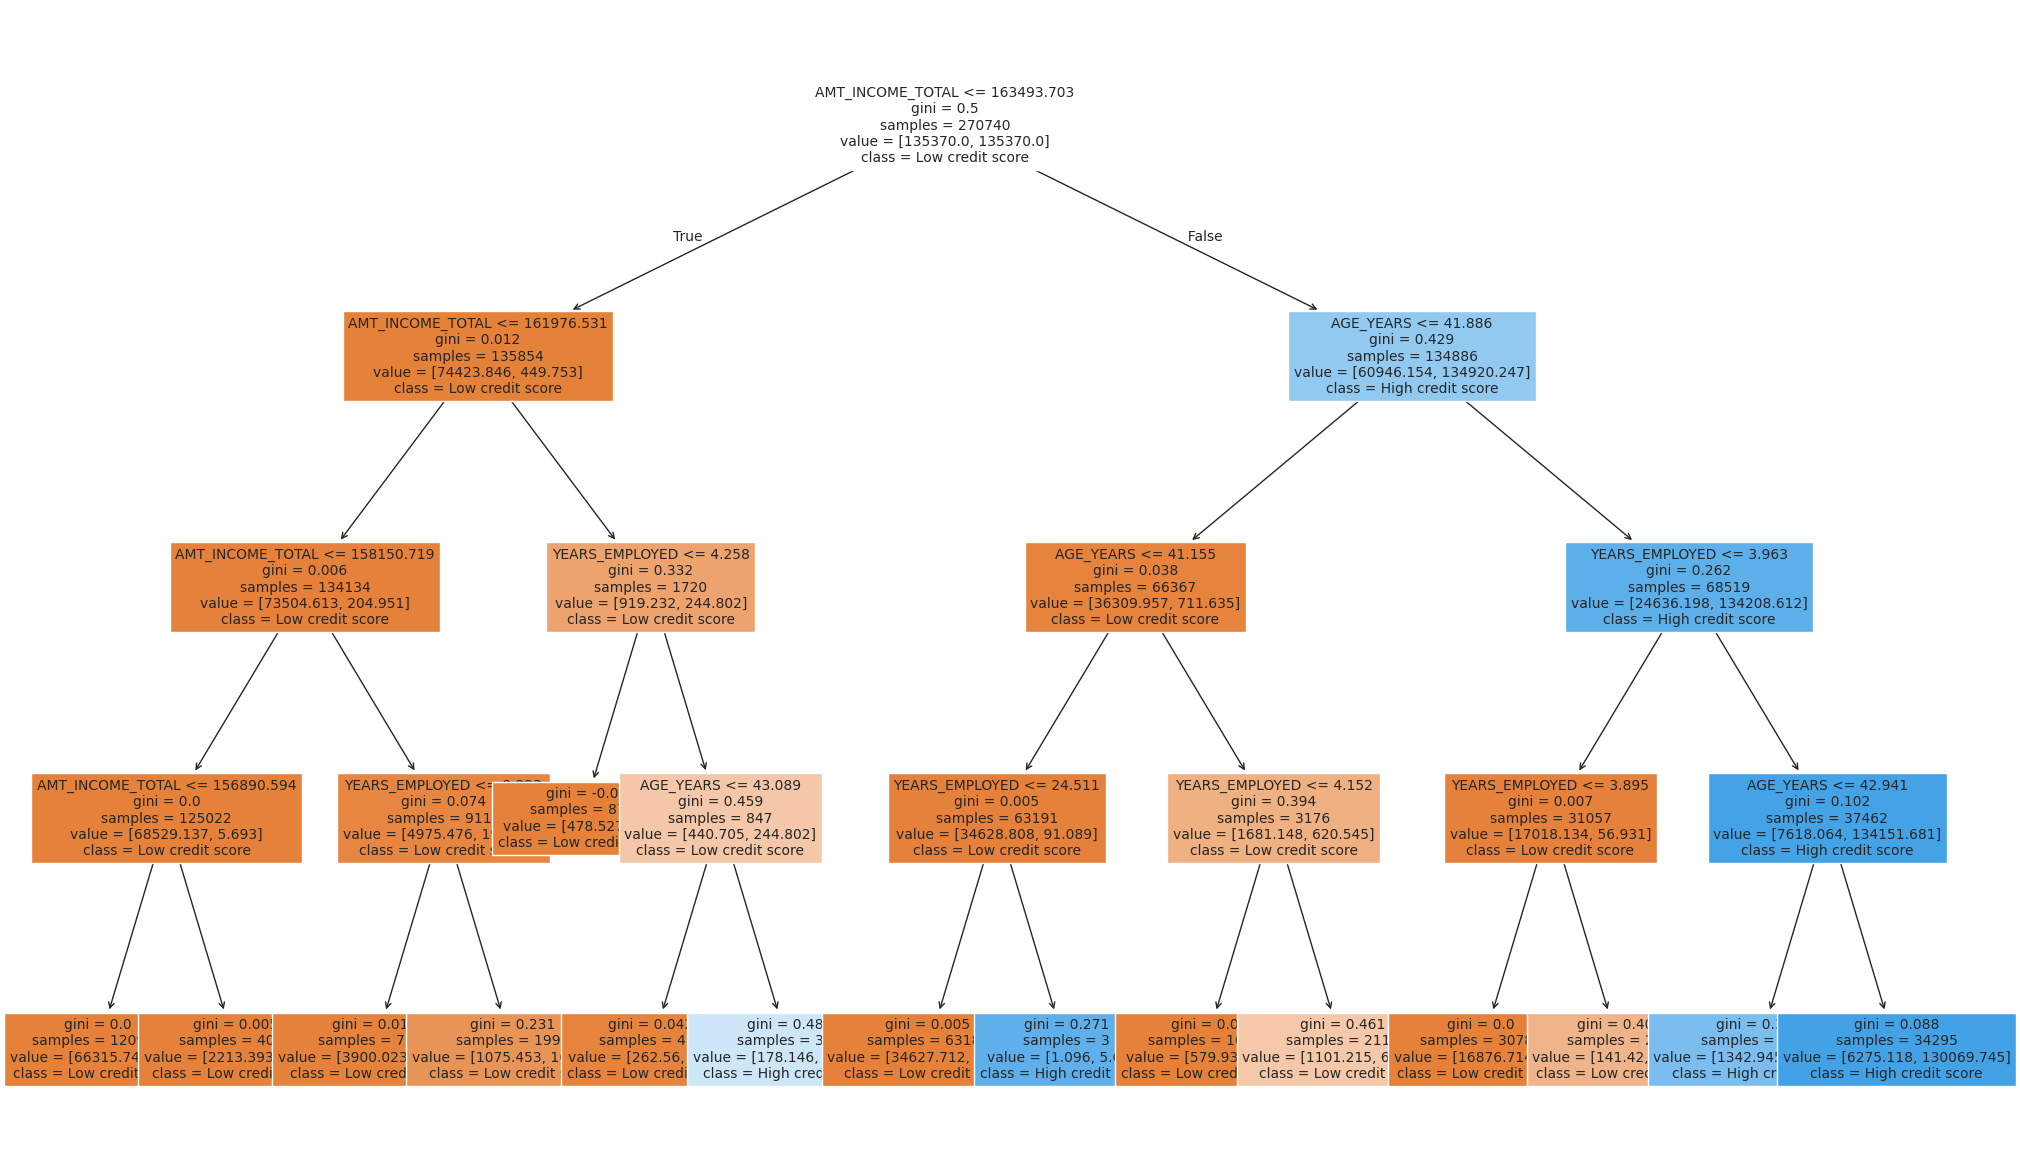

In [ ]:
# Extract the classifier and the preprocessor from the pipeline
dt_classifier = pipeline_dt.named_steps['classifier']
dt_preprocessor = pipeline_dt.named_steps['preprocessor']

# Create an empty list for the features and obtain all feature names
feature_names = []

# Add numerical features to the list
feature_names.extend(numerical_features)

# Add categorical features to the list
ohe = dt_preprocessor.named_transformers_['categorical']
feature_names.extend(list(ohe.get_feature_names_out(categorical_features)))

# Obtain all features from X array and add them to the list
all_features = X.columns.tolist()
preprocessed_features = set(numerical_features + categorical_features)
other_features = [col for col in all_features if col not in preprocessed_features]
feature_names.extend(other_features)

# Define class names for the target variable
class_names = ['Low credit score', 'High credit score']

plt.figure(figsize = (25, 15))
plot_tree(dt_classifier,
          feature_names = feature_names,
          class_names = class_names,
          filled = True,
          fontsize = 10)
plt.show()

In questo modo, la banca potrà fornire una motivazione al cliente nel caso in cui il rilascio della carta di credito gli venisse negato per bassa affidabilità creditizia.